In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [14]:
df = pd.read_csv('/workspaces/steel_stock_management/data/inventory_df.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 370 entries, 0 to 369
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       370 non-null    str    
 1   material    370 non-null    str    
 2   inventario  370 non-null    float64
dtypes: float64(1), str(2)
memory usage: 8.8 KB


In [15]:
df = df.sort_values(["material", "fecha"])

df["cambio_diario"] = (
    df.groupby("material")["inventario"]
      .diff()
)

df["consumo"] = -df["cambio_diario"]
df.loc[df["consumo"] < 0, "consumo"] = 0
df["consumo"] = df["consumo"].fillna(0)

df.head()

,fecha,material,inventario,cambio_diario,consumo
4,2026-05-19,ALAMBRE RECOCIDO,1924.63,NaN,0.0
14,2026-05-20,ALAMBRE RECOCIDO,1924.63,0.0,-0.0
24,2026-05-21,ALAMBRE RECOCIDO,1674.63,-250.0,250.0
34,2026-05-22,ALAMBRE RECOCIDO,1674.63,0.0,-0.0
44,2026-05-23,ALAMBRE RECOCIDO,1667.63,-7.0,7.0


In [ ]:
mat["daily_change"] = mat["inventario"].diff()
consumption = -mat["daily_change"]
consumption = consumption[consumption > 0]
avg = consumption.mean()

,fecha,material,inventario
0,2026-05-19,ARMEX DE 15 x 15,551.00
1,2026-05-19,ARMEX DE 15 x 20,9.00
2,2026-05-19,"VARILLA CORRUGADA 3/8""",1148.00
3,2026-05-19,"VARILLA CORRUGADA 1/2""",511.00
4,2026-05-19,ALAMBRE RECOCIDO,1924.63


In [22]:
material = "ARMEX DE 15 x 20"

mat = df[df["material"] == material].copy()

mat["fecha"] = pd.to_datetime(mat["fecha"])
mat = mat.sort_values("fecha")

series = mat.set_index("fecha")["consumo"]

series = series.asfreq("D")

series = series.fillna(0)

series.head()



fecha
2026-05-19    0.0
2026-05-20   -0.0
2026-05-21   -0.0
2026-05-22   -0.0
2026-05-23    2.0
Freq: D, Name: consumo, dtype: float64

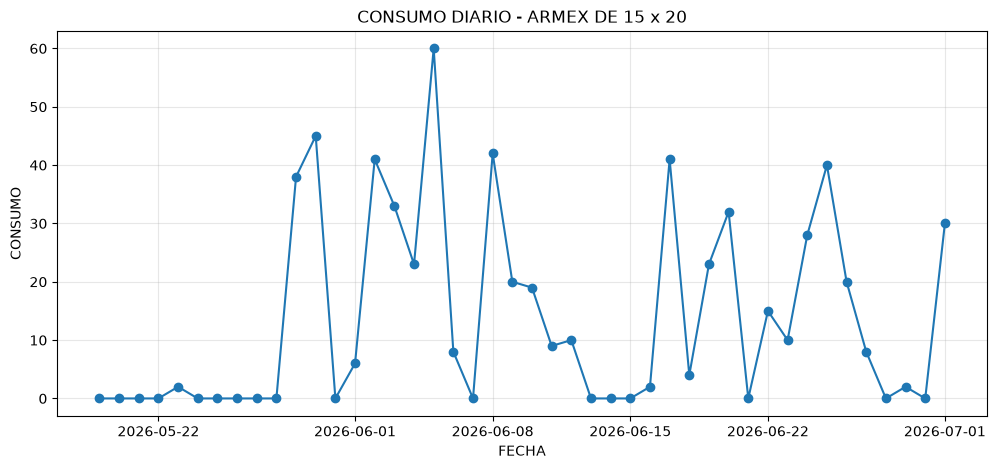

In [23]:
plt.figure(figsize=(12,5))
plt.plot(series, marker="o")
plt.title(f"CONSUMO DIARIO - {material}")
plt.xlabel("FECHA")
plt.ylabel("CONSUMO")
plt.grid(True, alpha=0.3)
plt.show()


In [25]:
def adf_test(series):
    result = adfuller(series.dropna())

    print("ADF Statistic:", result[0])
    print("p-value:", result[1])

    if result[1] < 0.05:
        print("ESTACIONARIO")
    else:
        print("NO ESTACIONARIO")

adf_test(series)

ADF Statistic: -4.196094918036302
p-value: 0.0006690012835443952
ESTACIONARIO


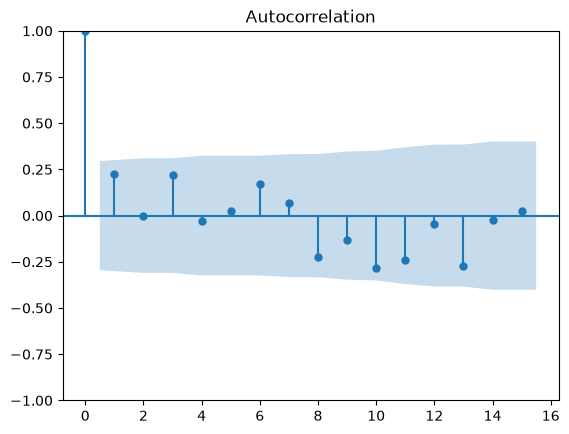

In [26]:
d = 0
series_for_acf = series

plot_acf(series_for_acf, lags=15)
plt.show()

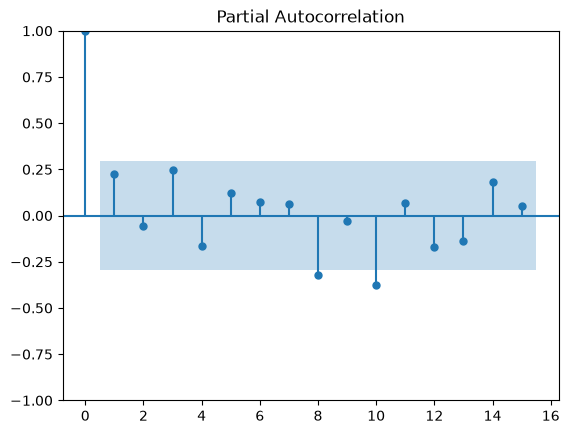

In [27]:
plot_pacf(series_for_acf, lags=15, method="ywm")
plt.show()

In [28]:
train = series[:-7]
test = series[-7:]

print("Train size:", len(train))
print("Test size:", len(test))

Train size: 37
Test size: 7


In [29]:
order = (1, d, 1)

model = ARIMA(train, order=order)
fit = model.fit()

print(fit.summary())

                               SARIMAX Results                                
Dep. Variable:                consumo   No. Observations:                   37
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -152.906
Date:                Thu, 02 Jul 2026   AIC                            313.811
Time:                        03:29:02   BIC                            320.255
Sample:                    05-19-2026   HQIC                           316.083
                         - 06-24-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.8382      4.289      3.227      0.001       5.432      22.244
ar.L1         -0.5132      0.235     -2.184      0.029      -0.974      -0.053
ma.L1          0.9997     28.806      0.035      0.9

In [30]:
forecast = fit.forecast(steps=len(test))

comparison = pd.DataFrame({
    "actual": test,
    "forecast": forecast
})

comparison

,actual,forecast
2026-06-25,40.0,19.668730
2026-06-26,20.0,10.845819
2026-06-27,8.0,15.373899
2026-06-28,0.0,13.050005
2026-06-29,2.0,14.242670
2026-06-30,-0.0,13.630572
2026-07-01,30.0,13.944712


In [31]:
mae = mean_absolute_error(comparison["actual"], comparison["forecast"])
rmse = np.sqrt(mean_squared_error(comparison["actual"], comparison["forecast"]))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 13.12
RMSE: 13.71


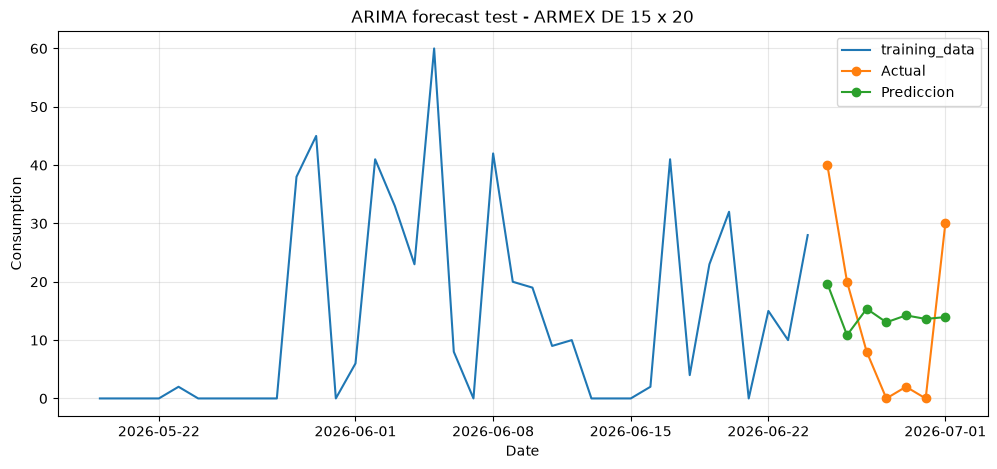

In [33]:
plt.figure(figsize=(12,5))

plt.plot(train.index, train, label="training_data")
plt.plot(test.index, test, label="Actual", marker="o")
plt.plot(forecast.index, forecast, label="Prediccion", marker="o")

plt.title(f"ARIMA forecast test - {material}")
plt.xlabel("Date")
plt.ylabel("Consumption")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [34]:
def try_arima_orders(series, d, test_days=7):
    train = series[:-test_days]
    test = series[-test_days:]

    results = []

    for p in range(0, 4):
        for q in range(0, 4):
            try:
                model = ARIMA(train, order=(p, d, q))
                fit = model.fit()

                forecast = fit.forecast(steps=len(test))

                mae = mean_absolute_error(test, forecast)
                rmse = np.sqrt(mean_squared_error(test, forecast))

                results.append({
                    "order": (p, d, q),
                    "aic": fit.aic,
                    "bic": fit.bic,
                    "mae": mae,
                    "rmse": rmse
                })

            except:
                continue

    results_df = pd.DataFrame(results)
    return results_df.sort_values("mae")

In [35]:
results = try_arima_orders(series, d=0, test_days=7)
results

/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("M

,order,aic,bic,mae,rmse
15,"(3, 0, 3)",316.409330,329.296673,11.321784,12.398184
1,"(0, 0, 1)",318.157538,322.990292,12.811345,13.837052
2,"(0, 0, 2)",316.505644,322.949316,12.857916,13.301677
8,"(2, 0, 0)",320.444550,326.888221,12.937941,14.095658
4,"(1, 0, 0)",318.466622,323.299376,12.941111,14.128823
10,"(2, 0, 2)",317.280860,326.946368,13.103966,13.680698
5,"(1, 0, 1)",313.811217,320.254888,13.119698,13.707580
6,"(1, 0, 2)",315.772284,323.826873,13.202088,13.785686
9,"(2, 0, 1)",315.736257,323.790846,13.282358,13.860933
0,"(0, 0, 0)",317.927750,321.149586,13.401544,14.837247


In [36]:
best_order = results.iloc[0]["order"]

final_model = ARIMA(series, order=best_order)
final_fit = final_model.fit()

print("Best order:", best_order)
print(final_fit.summary())

Best order: (3, 0, 3)
                               SARIMAX Results                                
Dep. Variable:                consumo   No. Observations:                   44
Model:                 ARIMA(3, 0, 3)   Log Likelihood                -178.199
Date:                Thu, 02 Jul 2026   AIC                            372.399
Time:                        03:31:15   BIC                            386.672
Sample:                    05-19-2026   HQIC                           377.692
                         - 07-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.9465      5.041      2.767      0.006       4.066      23.827
ar.L1         -0.7714      0.701     -1.100      0.271      -2.146       0.603
ar.L2          0.3415      1.0

/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [38]:
forecast_days = 15

future_forecast = final_fit.forecast(steps=forecast_days)

future_forecast = future_forecast.clip(lower=0)

future_forecast

2026-07-02    26.081107
2026-07-03     6.827688
2026-07-04    19.494017
2026-07-05    12.581188
2026-07-06    13.758552
2026-07-07    16.068739
2026-07-08    11.643931
2026-07-09    16.364592
2026-07-10    12.229723
2026-07-11    15.082342
2026-07-12    13.549167
2026-07-13    13.884701
2026-07-14    14.358787
2026-07-15    13.432364
2026-07-16    14.456666
Freq: D, Name: predicted_mean, dtype: float64

In [39]:
forecast_days = 15

future_forecast = final_fit.forecast(steps=forecast_days)

future_forecast = future_forecast.clip(lower=0)

future_forecast

2026-07-02    26.081107
2026-07-03     6.827688
2026-07-04    19.494017
2026-07-05    12.581188
2026-07-06    13.758552
2026-07-07    16.068739
2026-07-08    11.643931
2026-07-09    16.364592
2026-07-10    12.229723
2026-07-11    15.082342
2026-07-12    13.549167
2026-07-13    13.884701
2026-07-14    14.358787
2026-07-15    13.432364
2026-07-16    14.456666
Freq: D, Name: predicted_mean, dtype: float64

In [40]:
def arima_inventory_recommendation(
    df,
    material,
    date_col="fecha",
    demand_col="consumo",
    inventory_col="inventario",
    forecast_days=15,
    test_days=7,
    d=0,
    lead_time_days=7,
    target_days=15,
    safety_multiplier=1.65
):
    mat = df[df["material"] == material].copy()

    mat[date_col] = pd.to_datetime(mat[date_col])
    mat = mat.sort_values(date_col)

    series = mat.set_index(date_col)[demand_col]
    series = series.asfreq("D").fillna(0)

    train = series[:-test_days]
    test = series[-test_days:]

    results = []

    for p in range(0, 4):
        for q in range(0, 4):
            try:
                model = ARIMA(train, order=(p, d, q))
                fit = model.fit()

                forecast = fit.forecast(steps=len(test))
                forecast = forecast.clip(lower=0)

                mae = mean_absolute_error(test, forecast)
                rmse = np.sqrt(mean_squared_error(test, forecast))

                results.append({
                    "order": (p, d, q),
                    "aic": fit.aic,
                    "bic": fit.bic,
                    "mae": mae,
                    "rmse": rmse
                })

            except:
                pass

    results_df = pd.DataFrame(results).sort_values("mae")

    best_order = results_df.iloc[0]["order"]

    final_model = ARIMA(series, order=best_order)
    final_fit = final_model.fit()

    future_forecast = final_fit.forecast(steps=forecast_days)
    future_forecast = future_forecast.clip(lower=0)

    current_inventory = mat[inventory_col].iloc[-1]

    std_daily_demand = series.std()

    demand_during_lead_time = future_forecast[:lead_time_days].sum()

    safety_stock = safety_multiplier * std_daily_demand * np.sqrt(lead_time_days)

    reorder_point = demand_during_lead_time + safety_stock

    target_stock = future_forecast[:target_days].sum() + safety_stock

    quantity_to_buy = max(0, target_stock - current_inventory)

    buy_now = current_inventory <= reorder_point

    recommendation = {
        "material": material,
        "best_order": best_order,
        "current_inventory": round(current_inventory, 2),
        "forecasted_demand_next_days": round(future_forecast.sum(), 2),
        "demand_during_lead_time": round(demand_during_lead_time, 2),
        "safety_stock": round(safety_stock, 2),
        "reorder_point": round(reorder_point, 2),
        "target_stock": round(target_stock, 2),
        "buy_now": buy_now,
        "recommended_quantity_to_buy": round(quantity_to_buy, 2),
        "mae": round(results_df.iloc[0]["mae"], 2),
        "rmse": round(results_df.iloc[0]["rmse"], 2)
    }

    return recommendation, results_df, future_forecast

In [41]:
recommendation, model_results, forecast = arima_inventory_recommendation(
    df,
    material="ARMEX DE 15 x 20",
    d=0,
    lead_time_days=7,
    target_days=15
)

recommendation

/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("M

{'material': 'ARMEX DE 15 x 20',
 'best_order': (3, 0, 3),
 'current_inventory': np.float64(50.0),
 'forecasted_demand_next_days': np.float64(219.81),
 'demand_during_lead_time': np.float64(106.46),
 'safety_stock': np.float64(73.0),
 'reorder_point': np.float64(179.46),
 'target_stock': np.float64(292.81),
 'buy_now': np.True_,
 'recommended_quantity_to_buy': np.float64(242.81),
 'mae': np.float64(11.32),
 'rmse': np.float64(12.4)}

In [42]:
all_recommendations = []

for material in df["material"].unique():
    try:
        rec, results, forecast = arima_inventory_recommendation(
            df,
            material=material,
            d=0,
            lead_time_days=7,
            target_days=15
        )

        all_recommendations.append(rec)

    except Exception as e:
        print(material, "failed:", e)

recommendations_df = pd.DataFrame(all_recommendations)

recommendations_df.sort_values("buy_now", ascending=False)

/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
/workspaces/steel_stock_management/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting pa

,material,best_order,current_inventory,forecasted_demand_next_days,demand_during_lead_time,safety_stock,reorder_point,target_stock,buy_now,recommended_quantity_to_buy,mae,rmse
3,ARMEX DE 15 x 20,"(3, 0, 3)",50.00,219.81,106.46,73.00,179.46,292.81,True,242.81,11.32,12.40
5,"CLAVO PARA MADERA DE 2 1/2""","(0, 0, 3)",94.20,129.62,50.84,71.24,122.08,200.86,True,106.66,15.40,18.42
7,MALLA ELECTROSOLDADA 6-6-10/10,"(0, 0, 1)",269.30,2045.38,966.36,743.00,1709.36,2788.39,True,2519.09,133.59,140.08
0,ALAMBRE RECOCIDO,"(0, 0, 0)",924.37,733.64,342.36,358.02,700.38,1091.65,False,167.28,61.95,66.73
1,ALAMBRON,"(3, 0, 3)",1219.50,709.15,319.78,402.72,722.51,1111.88,False,0.00,32.71,52.47
2,ARMEX DE 15 x 15,"(0, 0, 3)",259.00,98.50,44.93,41.63,86.56,140.13,False,0.00,4.62,5.07
4,"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG","(3, 0, 3)",242.00,151.30,76.41,92.69,169.10,243.99,False,1.99,6.43,8.14
6,"CLAVO PARA MADERA DE 4""","(3, 0, 3)",212.30,60.78,29.16,69.70,98.86,130.48,False,0.00,21.48,39.54
8,"VARILLA CORRUGADA 1/2""","(0, 0, 3)",462.00,197.77,97.72,92.29,190.01,290.06,False,0.00,14.60,15.18
9,"VARILLA CORRUGADA 3/8""","(0, 0, 0)",449.00,458.18,213.82,175.04,388.85,633.22,False,184.22,39.56,58.01
